# MontePython chain analysis with GetDist

Analyses one MontePython output folder (e.g. `with_cosmopower/chains/model_lcdm__param_two_bins`) and, optionally, overlays others.

1. **Setup**: chain folder, burn-in, comparison chains
2. **Read `log.param`**: priors, scales, fixed bin edges `l_switch*`, fiducial file
3. **Load with GetDist**: rescale (`omega_b` → physical), set prior ranges, add Δω_m derived params
4. **Convergence**: acceptance, Gelman–Rubin per parameter, effective samples, traces
5. **Constraints**: marginalised table, pulls vs fiducial, best fit
6. **Plots**: triangle, ω_m per bin, ω_m vs ℓ
7. **ΛCDM consistency test**: are all ω_m bins equal?
8. **Comparison** with other chains (other bin counts, CLASS vs CosmoPower)

Run it from the `omega_m/` root (paths are relative), on the Mac or on Hive.

## 1. Setup

In [1]:
from pathlib import Path
import re, ast, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as sps
import getdist
from getdist import loadMCSamples, plots
print("getdist", getdist.__version__)

# ---- edit here -------------------------------------------------------------
#CHAIN_DIR = Path("with_cosmopower/chains/model_lcdm__param_two_bins")
CHAIN_DIR = Path("with_cosmopower/chains/model_lcdm_from_class__param_one_bin")

BURN_IN = 0.3          # fraction of each chain dropped (GetDist ignore_rows)
RESCALE = True         # multiply columns by the log.param 'scale' (100*omega_b -> omega_b)
SAVE_FIGS = True       # figures go to CHAIN_DIR/plots/
BIN_DIFFS = "all"      # omega_m bin differences to add: "all" pairs i>j, or "adjacent" (i, i-1) plus all (i, 0)

# Other chains to overlay in section 8: {legend label: folder}. Empty dict = skip.
COMPARE = {
    "1 bin":  Path("with_cosmopower/chains/model_lcdm__param_one_bin"),
    # "3 bins": Path("with_cosmopower/chains/model_lcdm__param_three_bins"),
    # "CLASS, 2 bins": Path("with_class/chains/model_lcdm__param_two_bins"),
}

# Project root used to re-map cluster paths in log.param (/home/mcbella/omega_m/...) to this machine.
# None = guess from CHAIN_DIR (<root>/<pipeline>/chains/<run>).
PROJECT_ROOT = None
# ----------------------------------------------------------------------------

CHAIN_DIR = CHAIN_DIR.expanduser().resolve()
FIG_DIR = CHAIN_DIR / "plots"
if SAVE_FIGS:
    FIG_DIR.mkdir(exist_ok=True)

def savefig(fig, name):
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

getdist 1.7.5


## 2. Read `log.param`

MontePython rows are `[mean, min, max, sigma, scale, role]`; `sigma = 0` means fixed (the `l_switch*` bin edges). `min/max = -1` or `None` means unbounded.
The fiducial file header (written by `make_fiducial.py`) gives the true values for the mock.

In [2]:
def read_log_param(chain_dir):
    # Parse data.parameters and the likelihood's fiducial_file from a MontePython log.param.
    text = (Path(chain_dir) / "log.param").read_text()
    params = {}
    for name, row in re.findall(r"^data\.parameters\[['\"](.+?)['\"]\]\s*=\s*(\[.*?\])", text, re.M):
        row = ast.literal_eval(row.replace("None", "None"))
        mean, lo, hi, sigma, scale, role = row
        params[name] = dict(mean=mean, min=lo, max=hi, sigma=sigma, scale=scale, role=role)
    fid = re.findall(r"^\w+\.fiducial_file\s*=\s*['\"](.+?)['\"]", text, re.M)
    return params, (fid[-1] if fid else None)   # last assignment wins, as in MontePython

def resolve_path(p, chain_dir):
    # Map a path written on another machine (e.g. Hive) onto this one.
    p = Path(p)
    if p.exists():
        return p
    root = Path(PROJECT_ROOT) if PROJECT_ROOT else Path(chain_dir).resolve().parents[2]
    parts = p.parts
    for i, part in enumerate(parts):
        if part.startswith("with_"):
            cand = root.joinpath(*parts[i:])
            if cand.exists():
                return cand
    return None

def read_fiducial(path):
    # Parse '# Fiducial parameters, pipeline = ..., omega_b = 0.0224, ...' (physical units).
    if path is None:
        return {}
    header = Path(path).open().readline()
    out = {}
    for key, val in re.findall(r"([\w^{}]+)\s*=\s*([^,]+)", header):
        try:
            out[key] = float(val)
        except ValueError:
            pass
    return out

def bin_edges(params):
    # Multipole bins: bin 0 = [2, l_switch1], bin i = (l_switch_i, l_switch_{i+1}].
    sw = sorted((int(k[len("l_switch"):]), v["mean"]) for k, v in params.items() if k.startswith("l_switch"))
    edges = [2] + [int(v) for _, v in sw]
    return [(edges[i] if i == 0 else edges[i] + 1, edges[i + 1]) for i in range(len(edges) - 1)]

def fiducial_omega_m_steps(fid):
    # Fiducial omega_m as (lmin, lmax, value) segments, from the fiducial header.
    sw = sorted((int(k[len("l_switch"):]), v) for k, v in fid.items() if k.startswith("l_switch"))
    om = sorted((int(k[len("omega_m"):]), v) for k, v in fid.items() if re.fullmatch(r"omega_m\d+", k))
    if not om:
        return []
    edges = [2] + [int(v) for _, v in sw]
    return [(edges[i] if i == 0 else edges[i] + 1, edges[i + 1], om[i][1]) for i in range(len(om))]

def fiducial_value(name, bins=None):
    # True value of a chain parameter, or None if unknown (e.g. an omega_m bin straddling a fiducial bin edge).
    bins = BINS if bins is None else bins
    if name == "H0" and "h" in FID:
        return 100 * FID["h"]
    m = re.fullmatch(r"(d?)omega_m(\d+)(?:_(\d+))?", name)
    if m and FID_STEPS:
        def true_om(i):
            lo, hi = bins[i]
            vals = {v for a, b, v in FID_STEPS if not (b < lo or a > hi)}
            return vals.pop() if len(vals) == 1 else None
        i = int(m.group(2))
        if m.group(1):                       # Delta omega_m = omega_m_i - omega_m_j (j = 0 by default)
            a, b = true_om(i), true_om(int(m.group(3) or 0))
            return None if a is None or b is None else a - b
        return true_om(i)
    if name in FID:
        return FID[name] / (1 if RESCALE else LOGP.get(name, {}).get("scale", 1))
    return None

LOGP, fid_file = read_log_param(CHAIN_DIR)
FID_PATH = resolve_path(fid_file, CHAIN_DIR) if fid_file else None
FID = read_fiducial(FID_PATH)
BINS = bin_edges(LOGP)
FID_STEPS = fiducial_omega_m_steps(FID)

print("fiducial file:", fid_file, "->", FID_PATH)
print("fiducial values:", FID)
print("fitted omega_m bins (l ranges):", BINS)
print("fiducial omega_m steps:", FID_STEPS)
print()
print(f"{'param':<14}{'mean':>9}{'min':>8}{'max':>8}{'sigma':>9}{'scale':>7}  role")
for k, v in LOGP.items():
    print(f"{k:<14}{v['mean']!s:>9}{v['min']!s:>8}{v['max']!s:>8}{v['sigma']!s:>9}{v['scale']!s:>7}  {v['role']}"
          + ("   (fixed)" if v["sigma"] == 0 and v["role"] != "derived" else ""))

fiducial file: /home/mcbella/omega_m/with_cosmopower/model/lcdm.dat -> /Users/bellamarco01/uni/omega_m/with_cosmopower/model/lcdm.dat
fiducial values: {'omega_b': 0.0224, 'h': 0.674, 'tau_reio': 0.054, 'n_s': 0.965, 'ln10^{10}A_s': 3.044, 'l_max_scalars': 2508.0, 'omega_m0': 0.15, 'l_switch1': 2508.0}
fitted omega_m bins (l ranges): [(2, 968), (969, 2508)]
fiducial omega_m steps: [(2, 2508, 0.15)]

param              mean     min     max    sigma  scale  role
omega_b            2.24     1.9     2.6     0.02   0.01  cosmo
h                 0.674     0.6    0.75     0.01      1  cosmo
tau_reio          0.054    0.02     0.1    0.005      1  cosmo
n_s               0.965    0.92     1.0    0.004      1  cosmo
ln10^{10}A_s      3.044     2.9     3.2    0.015      1  cosmo
l_switch1           968     968     968        0      1  cosmo   (fixed)
l_switch2          2508    2508    2508        0      1  cosmo   (fixed)
omega_m0           0.15    0.05    0.25   0.0012      1  cosmo
omega_m1    

## 3. Load the chains with GetDist

MontePython writes `<root>_1.txt … <root>_N.txt` + `<root>.paramnames` with columns `multiplicity, -lnL, params…`, which GetDist reads directly.
If a folder holds several runs (different dates/N), the root with the most chain files (then the newest) is used — set `ROOT` by hand to override.

In [3]:
LABELS = {
    "omega_b": r"\omega_b", "h": "h", "tau_reio": r"\tau_\mathrm{reio}", "n_s": "n_s",
    "ln10^{10}A_s": r"\ln(10^{10}A_s)", "H0": r"H_0", "omega_cdm": r"\omega_\mathrm{cdm}",
}

def find_root(chain_dir):
    roots = {}
    for f in Path(chain_dir).glob("*.paramnames"):
        root = str(f)[: -len(".paramnames")]
        n = len(glob.glob(glob.escape(root) + "_[0-9]*.txt"))
        nonempty = [c for c in glob.glob(glob.escape(root) + "_[0-9]*.txt") if Path(c).stat().st_size > 0]
        if nonempty:
            roots[root] = (len(nonempty), max(Path(c).stat().st_mtime for c in nonempty))
    if not roots:
        raise FileNotFoundError(f"no MontePython chains in {chain_dir}")
    return max(roots, key=roots.get)

def load_mp(chain_dir, burn_in=BURN_IN, rescale=RESCALE, label=None):
    chain_dir = Path(chain_dir).expanduser().resolve()
    root = find_root(chain_dir)
    logp, _ = read_log_param(chain_dir)
    s = loadMCSamples(root, settings={"ignore_rows": burn_in}, no_cache=True)
    names = s.getParamNames().list()

    # rescale columns to physical units (MontePython passes value*scale to CLASS)
    if rescale:
        for i, n in enumerate(names):
            sc = logp.get(n, {}).get("scale", 1)
            if sc not in (1, 1.0):
                s.samples[:, i] *= sc
                s.paramNames.parWithName(n).label = LABELS.get(n, n)
        s.updateBaseStatistics()

    # labels
    for p in s.paramNames.names:
        if p.name in LABELS:
            p.label = LABELS[p.name]
        m = re.fullmatch(r"omega_m(\d+)", p.name)
        if m:
            p.label = rf"\omega_{{m,{m.group(1)}}}"

    # hard prior edges (needed for correct KDE near a boundary)
    ranges = {}
    for n in names:
        if n in logp and logp[n]["role"] != "derived":
            sc = logp[n]["scale"] if rescale else 1
            lo, hi = logp[n]["min"], logp[n]["max"]
            lo = None if lo in (None, -1) else lo * sc
            hi = None if hi in (None, -1) else hi * sc
            ranges[n] = (lo, hi)
    s.setRanges(ranges)

    # bin differences: domega_m{i} = omega_m_i - omega_m0 (used by the LCDM test),
    # domega_m{i}_{j} = omega_m_i - omega_m_j for 1 <= j < i (all pairs, or only j = i-1)
    oms = sorted([n for n in names if re.fullmatch(r"omega_m\d+", n)], key=lambda n: int(n[7:]))
    col = lambda i: s.samples[:, s.index[f"omega_m{i}"]].copy()
    nb = len(oms)
    for i in range(1, nb):
        s.addDerived(col(i) - col(0), name=f"domega_m{i}", label=rf"\omega_{{m,{i}}}-\omega_{{m,0}}")
    for i in range(2, nb):
        for j in range(1, i):
            if BIN_DIFFS == "all" or j == i - 1:
                s.addDerived(col(i) - col(j), name=f"domega_m{i}_{j}", label=rf"\omega_{{m,{i}}}-\omega_{{m,{j}}}")
    s.updateBaseStatistics()
    s.name_tag = label or chain_dir.name
    s.chain_dir, s.root_file, s.omega_m_names = chain_dir, root, oms
    return s

samples = load_mp(CHAIN_DIR)
ROOT = samples.root_file
OM = samples.omega_m_names
PARAMS = [n for n in samples.getParamNames().list() if not n.startswith("domega")]
print("root:", ROOT)
print("parameters:", samples.getParamNames().list())
print(f"{samples.numrows} rows after burn-in, total weight {samples.norm:.0f}")

/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_two_bins/2026-10-09_100000__1.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_two_bins/2026-10-09_100000__2.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_two_bins/2026-10-09_100000__3.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_two_bins/2026-10-09_100000__4.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_two_bins/2026-10-09_100000__5.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_two_bins/2026-10-09_100000__6.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_two_bins/2026-10-09_100000__7.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_two_bins/2026-10-09_100000__8.txt
Removed 0.3 as burn in
root: /Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_two_bins/2026-10-09_100000_
parameters: ['

## 4. Convergence

Acceptance rate = accepted points / steps (sum of multiplicities). Gelman–Rubin $R-1$ is computed per parameter across the separate chains after burn-in (MontePython's own criterion is $R-1 < 0.01$–$0.05$); GetDist's number is the worst eigenvalue of the full covariance.

In [4]:
chain_files = sorted(glob.glob(glob.escape(ROOT) + "_[0-9]*.txt"), key=lambda f: int(re.search(r"_(\d+)\.txt$", f).group(1)))
raw = [np.atleast_2d(np.loadtxt(f)) for f in chain_files if Path(f).stat().st_size > 0]
names = [n for n in samples.getParamNames().list() if not n.startswith("domega")]   # columns in the .txt files

print(f"{'chain':<8}{'accepted':>10}{'steps':>10}{'acc. rate':>11}{'min -lnL':>11}")
for f, c in zip(chain_files, raw):
    print(f"{Path(f).name.split('__')[-1]:<8}{len(c):>10}{c[:,0].sum():>10.0f}{len(c)/c[:,0].sum():>11.3f}{c[:,1].min():>11.3f}")

def weighted_gr(chains, col, burn):
    # Per-parameter Gelman-Rubin R-1 with multiplicity weights; chains = raw arrays.
    means, vars_, ns = [], [], []
    for c in chains:
        c = c[int(burn * len(c)):]
        w, x = c[:, 0], c[:, col]
        m = np.average(x, weights=w)
        means.append(m); vars_.append(np.average((x - m) ** 2, weights=w)); ns.append(w.sum())
    W = np.mean(vars_); B = np.var(means, ddof=1); n = np.mean(ns)
    return ((n - 1) / n * W + B) / W - 1

print("\nGelman-Rubin R-1 (per parameter):")
for j, n in enumerate(PARAMS):
    col = 2 + names.index(n)
    print(f"  {n:<14} {weighted_gr(raw, col, BURN_IN):.4f}")
try:
    print(f"\nGetDist worst-eigenvalue R-1: {samples.getGelmanRubin():.4f}")
except Exception as e:
    print("GetDist R-1 not available:", e)

print("\nEffective number of samples (GetDist, after burn-in):")
for n in PARAMS:
    try:
        print(f"  {n:<14} {samples.getEffectiveSamples(names.index(n)):.0f}")
    except Exception as e:
        print(f"  {n:<14} n/a ({e})"); break

chain     accepted     steps  acc. rate   min -lnL
1.txt        25168    100000      0.252      0.156
2.txt        25337    100000      0.253      0.126
3.txt        25128    100000      0.251      0.131
4.txt        25023    100000      0.250      0.113
5.txt        25266    100000      0.253      0.213
6.txt        25340    100000      0.253      0.156
7.txt        25138    100000      0.251      0.146
8.txt        25108    100000      0.251      0.084

Gelman-Rubin R-1 (per parameter):
  omega_b        0.0007
  h              0.0006
  tau_reio       0.0001
  n_s            0.0001
  ln10^{10}A_s   0.0001
  omega_m0       0.0003
  omega_m1       0.0003
  H0             0.0006

GetDist worst-eigenvalue R-1: 0.0018

Effective number of samples (GetDist, after burn-in):
  omega_b        26621
  h              24922
  tau_reio       26082
  n_s            24510
  ln10^{10}A_s   26030
  omega_m0       24807
  omega_m1       25182
  H0             24922


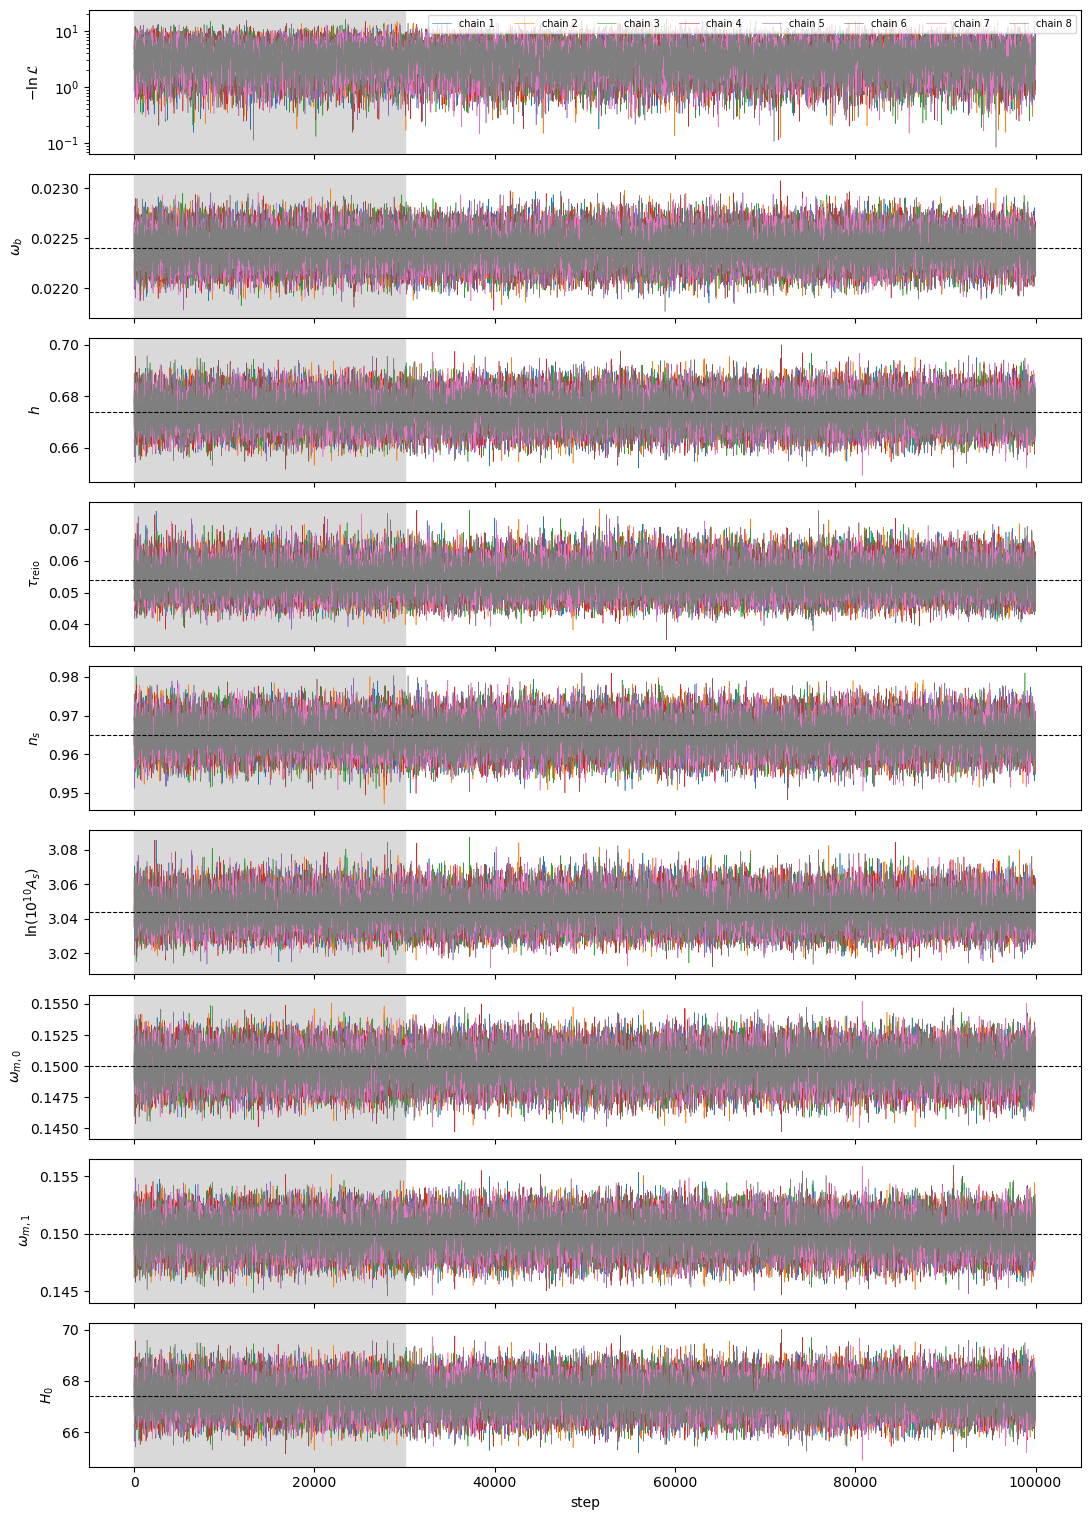

In [5]:
# Trace plots: x axis = MCMC step (multiplicity expanded), grey band = burn-in.
plot_params = PARAMS
fig, axes = plt.subplots(len(plot_params) + 1, 1, figsize=(11, 1.7 * (len(plot_params) + 1)), sharex=True)
for k, c in enumerate(raw):
    step = np.cumsum(c[:, 0])
    axes[0].plot(step, c[:, 1], lw=0.4, label=f"chain {k+1}", rasterized=True)
    for ax, n in zip(axes[1:], plot_params):
        y = c[:, 2 + names.index(n)] * (LOGP.get(n, {}).get("scale", 1) if RESCALE else 1)
        ax.plot(step, y, lw=0.4, rasterized=True)
axes[0].set_ylabel(r"$-\ln\mathcal{L}$")
axes[0].set_yscale("log")
for ax, n in zip(axes[1:], plot_params):
    ax.set_ylabel(f"${samples.parLabel(n)}$")
    fv = fiducial_value(n)
    if fv is not None:
        ax.axhline(fv, color="k", ls="--", lw=0.8)
nsteps = max(c[:, 0].sum() for c in raw)
for ax in axes:
    ax.axvspan(0, BURN_IN * nsteps, color="0.85", zorder=-1)
axes[-1].set_xlabel("step")
axes[0].legend(ncol=8, fontsize=7, loc="upper right")
fig.tight_layout()
savefig(fig, "traces")
plt.show()

## 5. Constraints

Pull = (mean − fiducial)/σ. For an ω_m bin the fiducial is the true ω_m over that ℓ range; if the fitted bin straddles a fiducial edge there is no single true value, so the pull is left blank (see the ω_m(ℓ) plot instead).

In [6]:
def constraint_table(s, params):
    ms = s.getMargeStats()
    print(f"{'param':<14}{'mean':>11}{'sigma':>10}{'68% lower':>11}{'68% upper':>11}{'95% lower':>11}{'95% upper':>11}{'fiducial':>11}{'pull':>8}")
    for n in params:
        p = ms.parWithName(n)
        fid = fiducial_value(n)
        pull = f"{(p.mean - fid)/p.err:+8.2f}" if fid is not None else f"{'':>8}"
        fs = f"{fid:11.5g}" if fid is not None else f"{'':>11}"
        print(f"{n:<14}{p.mean:11.5g}{p.err:10.2g}{p.limits[0].lower:11.5g}{p.limits[0].upper:11.5g}"
              f"{p.limits[1].lower:11.5g}{p.limits[1].upper:11.5g}{fs}{pull}")

constraint_table(samples, samples.getParamNames().list())
print()
for n in samples.getParamNames().list():
    print(samples.getInlineLatex(n, limit=1))

param                mean     sigma  68% lower  68% upper  95% lower  95% upper   fiducial    pull
omega_b          0.022406   0.00015   0.022261    0.02255   0.022123   0.022692     0.0224   +0.04
h                 0.67422    0.0055    0.66874     0.6797    0.66357    0.68511      0.674   +0.04
tau_reio         0.054516    0.0043   0.049871   0.058435   0.046537   0.063576      0.054   +0.12
n_s               0.96512    0.0037    0.96142    0.96881    0.95776    0.97244      0.965   +0.03
ln10^{10}A_s       3.0449    0.0083     3.0362     3.0526     3.0294      3.062      3.044   +0.11
omega_m0          0.14997    0.0012    0.14877    0.15118    0.14758    0.15237       0.15   -0.02
omega_m1          0.14997    0.0013    0.14868    0.15125    0.14743     0.1525       0.15   -0.02
H0                 67.422      0.55     66.874      67.97     66.357     68.511       67.4   +0.04
domega_m1      8.3441e-07   0.00056 -0.0005584  0.0005595 -0.0010987  0.0011146          0   +0.00

\omega_b 

In [7]:
# Best fit: highest-likelihood point in the chains (all rows, before burn-in) and MontePython's .bestfit if present.
allc = np.vstack(raw)
ib = np.argmin(allc[:, 1])
print(f"min -lnL = {allc[ib,1]:.4f}   ->  chi2_min = {2*allc[ib,1]:.3f}")
print("(fake_planck_realistic mocks are noiseless, so chi2_min ~ 0 when the model contains the fiducial)\n")
for n in names:
    v = allc[ib, 2 + names.index(n)] * (LOGP.get(n, {}).get("scale", 1) if RESCALE else 1)
    print(f"  {n:<14}{v:12.6g}")
bf = list(CHAIN_DIR.glob("*.bestfit"))
if bf:
    print("\nMontePython .bestfit:", bf[0].name)
    print(bf[0].read_text())

min -lnL = 0.0839   ->  chi2_min = 0.168
(fake_planck_realistic mocks are noiseless, so chi2_min ~ 0 when the model contains the fiducial)

  omega_b          0.0224379
  h                 0.675182
  tau_reio         0.0543882
  n_s               0.965533
  ln10^{10}A_s       3.04444
  omega_m0            0.1499
  omega_m1           0.14978
  H0                 67.5182


## 6. Plots

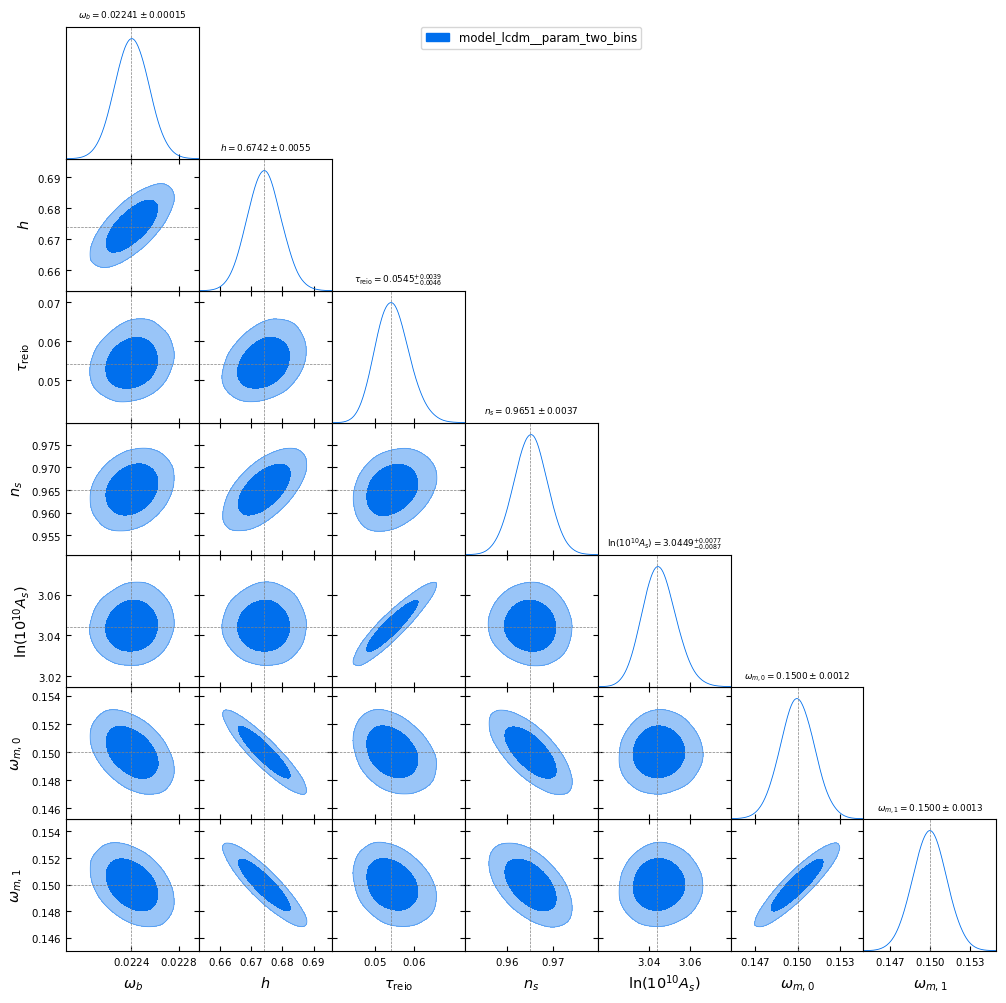

In [8]:
markers = {n: fiducial_value(n) for n in PARAMS if fiducial_value(n) is not None}

g = plots.get_subplot_plotter(width_inch=12)
g.settings.axes_fontsize = 11
g.settings.axes_labelsize = 14
g.settings.title_limit_fontsize = 10
g.triangle_plot([samples], [n for n in PARAMS if n != "H0"], filled=True,
                markers=markers, title_limit=1, legend_labels=[samples.name_tag])
savefig(g.fig, "triangle")
plt.show()

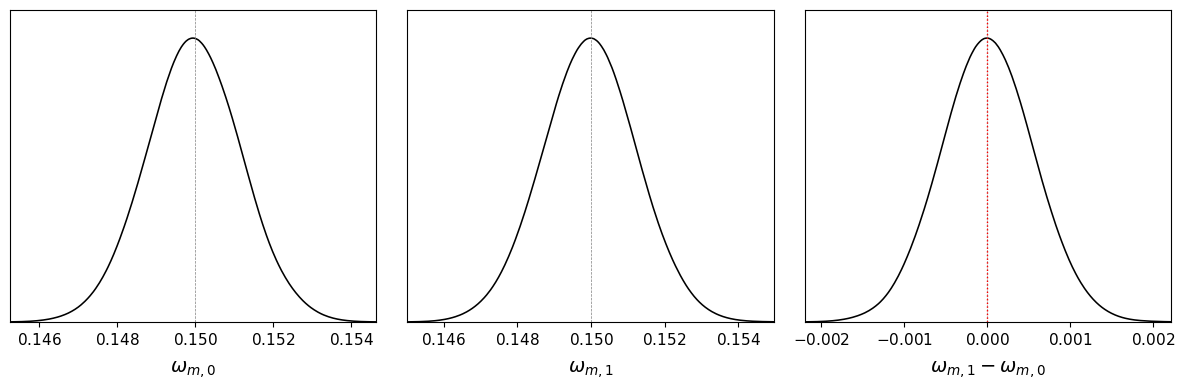

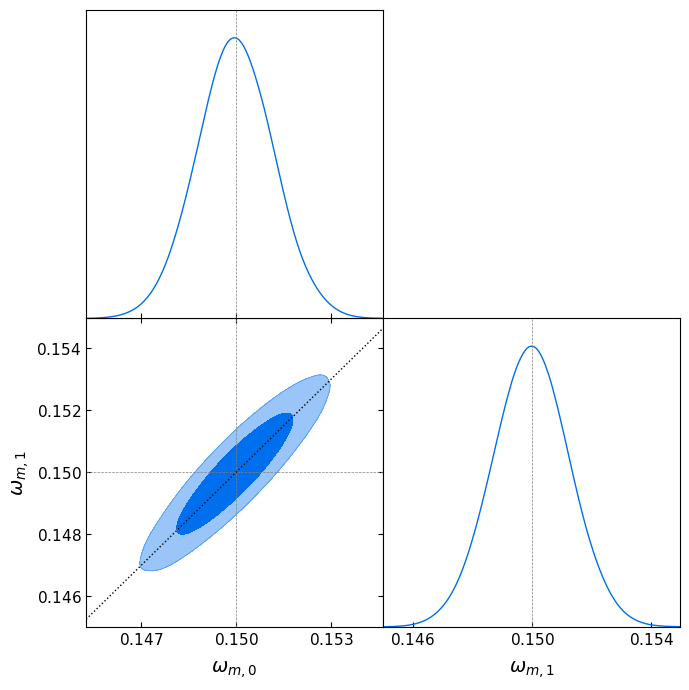

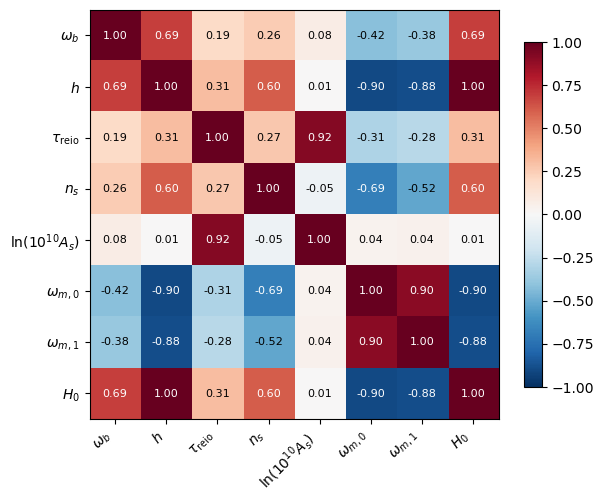

In [9]:
# omega_m bins: 1D marginals of every bin and every bin difference, then all bins against each other.
DIFFS = [n for n in samples.getParamNames().list() if n.startswith("domega")]
if OM:
    fid_om = {n: fiducial_value(n) for n in OM + DIFFS if fiducial_value(n) is not None}
    g = plots.get_subplot_plotter(width_inch=12)
    g.plots_1d(samples, OM + DIFFS, nx=max(3, len(OM)), markers=fid_om)
    for ax, n in zip(g.subplots.flat, OM + DIFFS):     # zero line on the differences
        if n in DIFFS:
            ax.axvline(0, color="r", ls=":", lw=1)
    savefig(g.fig, "omega_m_1d")
    plt.show()

    if len(OM) > 1:
        # triangle of the omega_m bins; dotted diagonal = equal omega_m (LCDM)
        g = plots.get_subplot_plotter(width_inch=3 + 2 * len(OM))
        g.triangle_plot(samples, OM, filled=True, markers={n: v for n, v in fid_om.items() if n in OM})
        for i in range(1, len(OM)):
            for j in range(i):
                ax = g.subplots[i, j]
                lo = max(ax.get_xlim()[0], ax.get_ylim()[0]); hi = min(ax.get_xlim()[1], ax.get_ylim()[1])
                if lo < hi:
                    ax.plot([lo, hi], [lo, hi], "k:", lw=1)
        savefig(g.fig, "omega_m_triangle")
        plt.show()

# Correlation matrix
corr = samples.getCorrelationMatrix()
idx = [names.index(n) for n in PARAMS]
corr = corr[np.ix_(idx, idx)]
fig, ax = plt.subplots(figsize=(1 + 0.7 * len(idx), 0.8 + 0.6 * len(idx)))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
lab = [f"${samples.parLabel(n)}$" for n in PARAMS]
ax.set_xticks(range(len(idx)), lab, rotation=45, ha="right"); ax.set_yticks(range(len(idx)), lab)
for i in range(len(idx)):
    for j in range(len(idx)):
        ax.text(j, i, f"{corr[i,j]:.2f}", ha="center", va="center", fontsize=8,
                color="w" if abs(corr[i, j]) > 0.6 else "k")
fig.colorbar(im, ax=ax, shrink=0.8)
savefig(fig, "correlation")
plt.show()

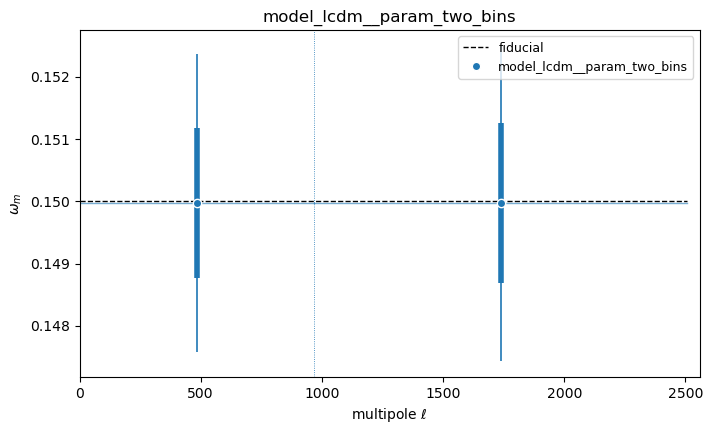

In [10]:
def plot_omega_m_vs_ell(sample_list, ax=None, colors=None):
    # One point per omega_m bin at the bin centre; horizontal bar = l range, thick/thin vertical bars = 68/95%.
    ax = ax or plt.gca()
    colors = colors or plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for j, (lo, hi, v) in enumerate(FID_STEPS):
        ax.plot([lo, hi], [v, v], "k--", lw=1, label="fiducial" if j == 0 else None, zorder=1)
    n = len(sample_list)
    for k, s in enumerate(sample_list):
        logp, _ = read_log_param(s.chain_dir)
        bins = bin_edges(logp)
        ms = s.getMargeStats()
        c = colors[k % len(colors)]
        for i, (lo, hi) in enumerate(bins):
            p = ms.parWithName(f"omega_m{i}")
            x = 0.5 * (lo + hi) + (k - (n - 1) / 2) * 40          # small offset between chains
            ax.plot([lo, hi], [p.mean] * 2, color=c, lw=1, alpha=0.6)
            ax.vlines(x, p.limits[1].lower, p.limits[1].upper, color=c, lw=1.2)
            ax.vlines(x, p.limits[0].lower, p.limits[0].upper, color=c, lw=4)
            ax.plot(x, p.mean, "o", color=c, mec="w", ms=6, label=s.name_tag if i == 0 else None, zorder=3)
        for lo, _ in bins[1:]:
            ax.axvline(lo - 0.5, color=c, ls=":", lw=0.6)
    ax.set_xlim(0, max(b for s in sample_list for _, b in bin_edges(read_log_param(s.chain_dir)[0])) + 50)
    ax.set_xlabel(r"multipole $\ell$")
    ax.set_ylabel(r"$\omega_m$")
    ax.legend(fontsize=9)
    return ax

if OM:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    plot_omega_m_vs_ell([samples], ax)
    ax.set_title(samples.name_tag)
    savefig(fig, "omega_m_vs_ell")
    plt.show()

## 7. ΛCDM consistency test

First every bin difference on its own (mean/σ, and vs the fiducial difference). Then the joint test.

Null hypothesis: all bins share one ω_m, i.e. $\Delta_i = \omega_{m,i}-\omega_{m,0} = 0$ for $i \ge 1$ (the other differences are combinations of these, so they are not added).
Gaussian approximation: $\chi^2 = \bar\Delta^T C_\Delta^{-1}\bar\Delta$ with $N_\mathrm{bins}-1$ d.o.f., converted to a PTE and an equivalent two-sided Gaussian significance.
The same statistic is also given against the *fiducial* Δ (should be consistent for a correct pipeline), and, as a non-Gaussian check, the posterior mass beyond the Δ = 0 point.

In [11]:
def lcdm_test(s, target=None):
    dn = [n for n in s.getParamNames().list() if re.fullmatch(r"domega_m\d+", n)]   # N-1 independent differences
    if not dn:
        print("single bin: nothing to test"); return
    X = np.column_stack([s.samples[:, s.index[n]] for n in dn])
    w = s.weights
    mu = np.average(X, axis=0, weights=w)
    C = np.atleast_2d(np.cov(X.T, aweights=w))
    t = np.zeros(len(dn)) if target is None else np.asarray(target)
    d = mu - t
    chi2 = float(d @ np.linalg.solve(C, d))
    pte = sps.chi2.sf(chi2, len(dn))
    nsig = sps.norm.isf(pte / 2)
    # posterior mass with Mahalanobis distance larger than that of the target point
    r2 = np.einsum("ij,ij->i", (X - mu) @ np.linalg.inv(C), X - mu)
    mass = np.sum(w[r2 > chi2]) / w.sum()
    print(f"  Delta = {np.array2string(mu, precision=5)}  sigma = {np.array2string(np.sqrt(np.diag(C)), precision=5)}")
    print(f"  chi2 = {chi2:.3f} for {len(dn)} dof  ->  PTE = {pte:.3g}  ({nsig:.2f} sigma)   "
          f"[posterior mass beyond: {mass:.3g}]")

# each bin difference on its own
ms = samples.getMargeStats()
print(f"{'difference':<26}{'mean':>11}{'sigma':>10}{'/sigma':>9}{'fiducial':>11}{'(mean-fid)/sigma':>18}")
for n in DIFFS:
    p = ms.parWithName(n); fv = fiducial_value(n)
    fs = f"{fv:11.4f}{(p.mean - fv)/p.err:+18.2f}" if fv is not None else ""
    print(f"{samples.parLabel(n):<26}{p.mean:11.5f}{p.err:10.5f}{p.mean/p.err:+9.2f}{fs}")
print()

print("joint test, all bins equal (Delta_i = omega_m_i - omega_m0 = 0):")
lcdm_test(samples)
fid_d = [fiducial_value(n) for n in samples.getParamNames().list() if re.fullmatch(r"domega_m\d+", n)]
if fid_d and None not in fid_d:
    print("\nvs fiducial Delta =", fid_d)
    lcdm_test(samples, fid_d)

difference                       mean     sigma   /sigma   fiducial  (mean-fid)/sigma
\omega_{m,1}-\omega_{m,0}     0.00000   0.00056    +0.00     0.0000             +0.00

joint test, all bins equal (Delta_i = omega_m_i - omega_m0 = 0):
  Delta = [8.34407e-07]  sigma = [0.00056]
  chi2 = 0.000 for 1 dof  ->  PTE = 0.999  (0.00 sigma)   [posterior mass beyond: 0.999]

vs fiducial Delta = [0.0]
  Delta = [8.34407e-07]  sigma = [0.00056]
  chi2 = 0.000 for 1 dof  ->  PTE = 0.999  (0.00 sigma)   [posterior mass beyond: 0.999]


## 8. Comparison with other chains

Overlay the chains in `COMPARE` (e.g. different binning, or the CLASS vs CosmoPower benchmark). Parameters missing from a chain are just not drawn for it.
For the benchmark, the shift between pipelines in units of σ is printed for shared parameters.

/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_one_bin/2026-10-09_100000__1.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_one_bin/2026-10-09_100000__2.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_one_bin/2026-10-09_100000__3.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_one_bin/2026-10-09_100000__4.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_one_bin/2026-10-09_100000__5.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_one_bin/2026-10-09_100000__6.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_one_bin/2026-10-09_100000__7.txt
/Users/bellamarco01/uni/omega_m/with_cosmopower/chains/model_lcdm__param_one_bin/2026-10-09_100000__8.txt
Removed 0.3 as burn in


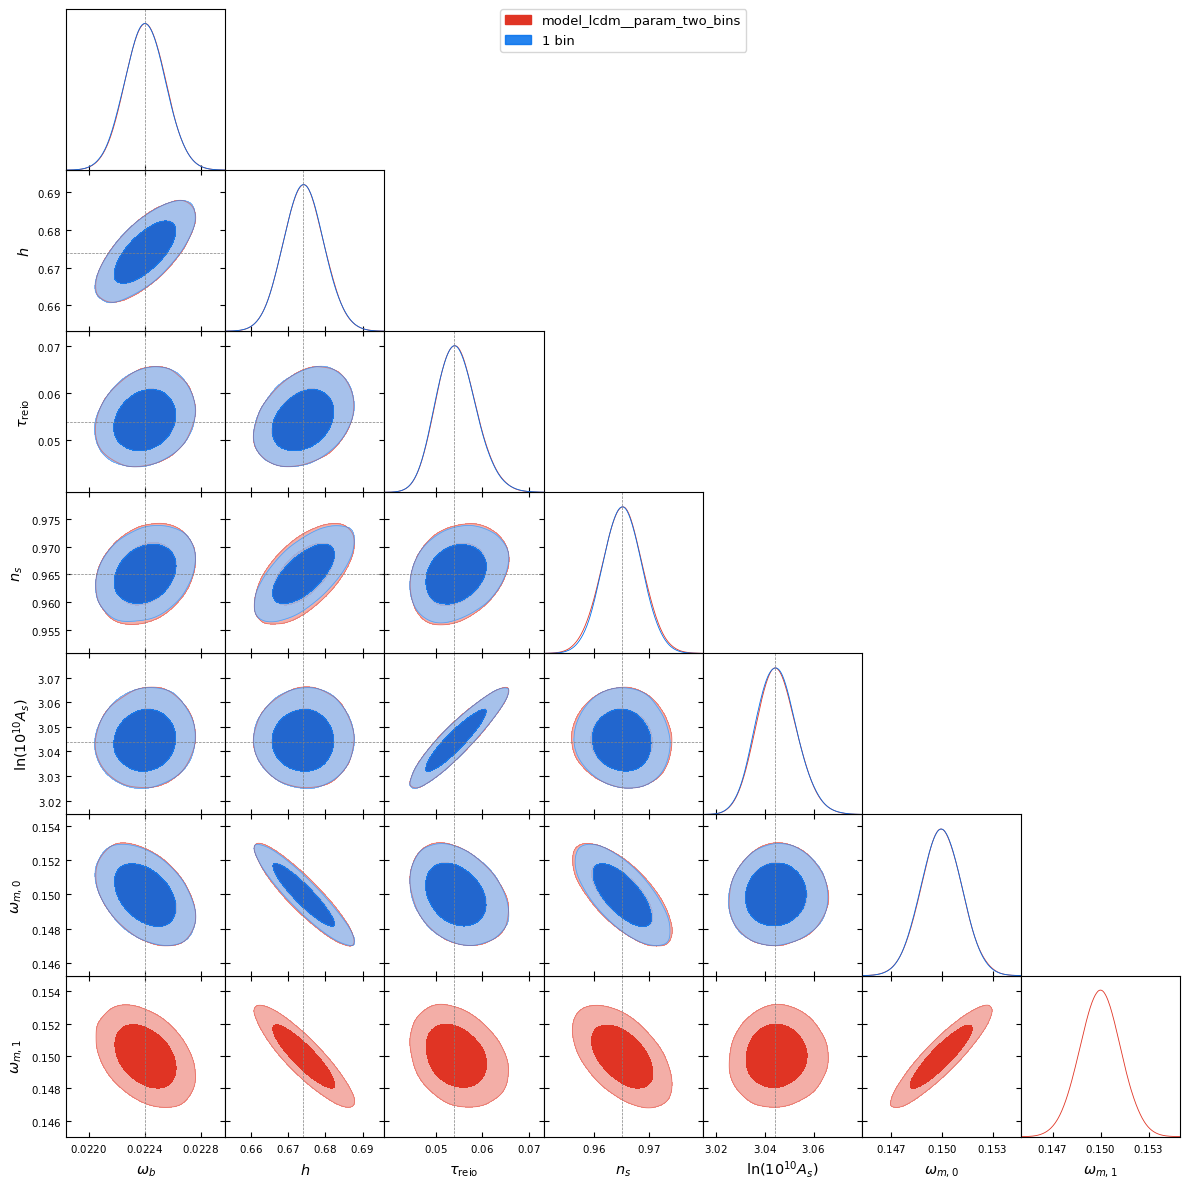

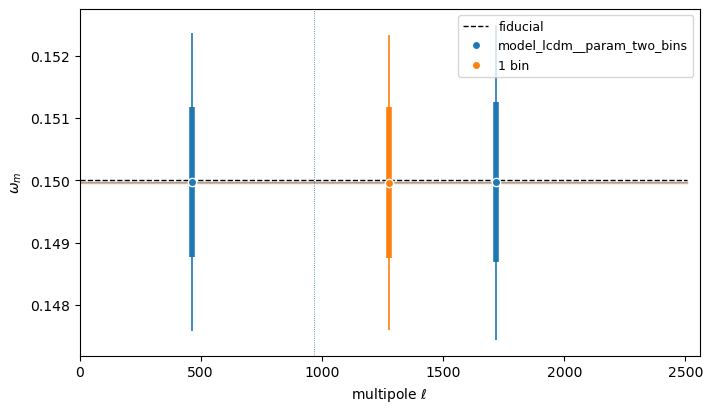

shift (other - this) / sigma_this, shared parameters:
param                      1 bin
omega_b            -0.01 (x1.01)
h                  -0.00 (x1.00)
tau_reio           -0.01 (x1.00)
n_s                +0.00 (x0.95)
ln10^{10}A_s       -0.01 (x1.01)
omega_m0           -0.01 (x1.00)
(xN = ratio of sigmas)


In [12]:
if COMPARE:
    others = [load_mp(d, label=lab) for lab, d in COMPARE.items()]
    allS = [samples] + others

    common = [n for n in PARAMS if n != "H0" and all(n in s.getParamNames().list() for s in allS)]
    union = list(dict.fromkeys(n for s in allS for n in s.getParamNames().list() if not n.startswith("domega") and n != "H0"))

    g = plots.get_subplot_plotter(width_inch=12)
    g.settings.legend_fontsize = 13
    g.triangle_plot(allS, union, filled=True, legend_labels=[s.name_tag for s in allS],
                    markers={n: fiducial_value(n) for n in union if fiducial_value(n) is not None and not n.startswith("omega_m")})
    savefig(g.fig, "compare_triangle")
    plt.show()

    if any(s.omega_m_names for s in allS):
        fig, ax = plt.subplots(figsize=(8, 4.5))
        plot_omega_m_vs_ell([s for s in allS if s.omega_m_names], ax)
        savefig(fig, "compare_omega_m_vs_ell")
        plt.show()

    print(f"shift (other - this) / sigma_this, shared parameters:")
    m0 = samples.getMargeStats()
    print(f"{'param':<14}" + "".join(f"{s.name_tag[:16]:>18}" for s in others))
    for n in common:
        p0 = m0.parWithName(n)
        row = ""
        for s in others:
            p = s.getMargeStats().parWithName(n)
            row += f"{(p.mean - p0.mean)/p0.err:+10.2f} (x{p.err/p0.err:4.2f})"
        print(f"{n:<14}{row}")
    print("(xN = ratio of sigmas)")

## Notes
- A chain folder can hold several runs (`<date>_<N>_`): only one root is loaded; check the printed root.
- `omega_b` is sampled as 100ω_b; with `RESCALE = True` everything here is physical ω_b, matching the fiducial header.
- GetDist caches nothing here (`no_cache=True`), so re-running after chains grow picks up new points.
- To export for a paper: `samples.getTable(limit=1).tableTex()`.